# Scheduler и ранняя остановка

Сравним обучение с постоянным `lr=0.003` и с `StepLR(step_size=300, gamma=0.5)`. В обоих случаях используем раннюю остановку после 150 эпох без улучшения validation.


## Ход работы

Один раз создаём данные и разбиение, затем подготавливаем одинаковую архитектуру для двух режимов обучения. В первом используем постоянный шаг Adam, во втором подключаем StepLR. В обоих режимах следим за validation и завершаем обучение после заданного числа эпох без улучшения.

Во время обучения сохраняем train loss, validation loss и learning rate. После запусков сравниваем последние ошибки с минимальными, находим лучшие эпохи и строим графики. Кривая learning rate позволяет проверить расписание, а validation показывает, как изменение шага связано с качеством модели.


### Библиотеки и генераторы случайности

Импортируем необходимые библиотеки. Для корректного сравнения вариантов используем один и тот же набор данных и начальную инициализацию модели.

In [2]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
import copy
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)


### Формируем обучающую и валидационную выборки

Генерируем функцию с шумом и один раз разделяем данные. Валидационная часть используется для решения об остановке, поэтому её нельзя считать независимым тестом после многократного подбора настроек.

In [3]:

# 1. Создаём данные
x = torch.linspace(-3, 3, 200).reshape(-1, 1)
y = torch.sin(3 * x) + 0.3 * x

# Добавляем шум
y_noisy = y + 0.15 * torch.randn_like(y)

# Разделяем на Train и Validation
indices = torch.randperm(200)

train_idx = indices[:160]
val_idx = indices[160:]

x_train = x[train_idx]
y_train = y_noisy[train_idx]

x_val = x[val_idx]
y_val = y_noisy[val_idx]


### Создаём одинаковую архитектуру для обоих запусков

Функция `create_model()` возвращает новую MLP. Мы проверяем влияние расписания шага, поэтому число слоёв и нейронов в двух сравниваемых вариантах оставляем одинаковыми.

In [4]:


# 2. Создаём нейросеть Very Deep
def create_model():
    return nn.Sequential(
        nn.Linear(1, 32),
        nn.Tanh(),
        nn.Linear(32, 32),
        nn.Tanh(),
        nn.Linear(32, 32),
        nn.Tanh(),
        nn.Linear(32, 1)
    )

best_val_loss = float("inf")
best_epoch = 0
best_weights = None

patience = 150
epochs_without_improvement = 0


### Функция обучения: Adam, StepLR и Early Stopping

 `StepLR` меняет `lr` по расписанию, а Early Stopping отслеживает лучшую валидационную ошибку, запоминает веса и может остановить обучение при отсутствии улучшений.

In [5]:

# 3. Функция обучения

def train_model(use_scheduler):

    torch.manual_seed(42)
    model = create_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003
    )

    loss_fn = nn.MSELoss()

    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=300,
            gamma=0.5
        )

    train_history = []
    val_history = []
    lr_history = []

    # Настройки Early Stopping
    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    patience = 150
    epochs_without_improvement = 0

    for epoch in range(1000):

        # ОБУЧЕНИЕ
        model.train()
        optimizer.zero_grad()

        prediction = model(x_train)
        loss = loss_fn(prediction, y_train)

        loss.backward()

        current_lr = optimizer.param_groups[0]["lr"]
        lr_history.append(current_lr)

        optimizer.step()

        if use_scheduler:
            scheduler.step()

        # ПРОВЕРКА
        model.eval()

        with torch.no_grad():
            val_prediction = model(x_val)
            val_loss = loss_fn(val_prediction, y_val)

        train_history.append(loss.item())
        val_history.append(val_loss.item())

        # EARLY STOPPING
        if val_loss.item() < best_val_loss:

            best_val_loss = val_loss.item()
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1:4d} | "
                f"LR: {current_lr:.6f} | "
                f"Train: {loss.item():.5f} | "
                f"Val: {val_loss.item():.5f}"
            )

        # Остановка, если нет улучшений
        if epochs_without_improvement >= patience:
            print(f"Early Stopping на эпохе {epoch + 1}")
            break

    # Восстанавливаем лучшие веса
    model.load_state_dict(best_weights)

    print("Лучшая эпоха:", best_epoch)
    print("Лучший Validation MSE:", round(best_val_loss, 5))
    print()

    return train_history, val_history, lr_history


### Запускаем обучение без расписания

In [6]:

# 4. Обучаем без Scheduler
print("БЕЗ SCHEDULER")

train1, val1, lr1 = train_model(False)


БЕЗ SCHEDULER
Epoch  100 | LR: 0.003000 | Train: 0.41665 | Val: 0.30282
Epoch  200 | LR: 0.003000 | Train: 0.04307 | Val: 0.03857
Epoch  300 | LR: 0.003000 | Train: 0.02844 | Val: 0.02864
Epoch  400 | LR: 0.003000 | Train: 0.02317 | Val: 0.02766
Epoch  500 | LR: 0.003000 | Train: 0.02104 | Val: 0.02891
Early Stopping на эпохе 514
Лучшая эпоха: 364
Лучший Validation MSE: 0.02716



### Запускаем обучение с StepLR

Во втором опыте параметры модели и начальные условия остаются такими же; меняется только расписание скорости обучения. Не предполагаем заранее, что Scheduler обязательно улучшит минимум Validation Loss.

In [7]:


# 5. Обучаем со Scheduler
print("\nСО SCHEDULER")

train2, val2, lr2 = train_model(True)



СО SCHEDULER
Epoch  100 | LR: 0.003000 | Train: 0.41665 | Val: 0.30282
Epoch  200 | LR: 0.003000 | Train: 0.04307 | Val: 0.03857
Epoch  300 | LR: 0.003000 | Train: 0.02844 | Val: 0.02864
Epoch  400 | LR: 0.001500 | Train: 0.02502 | Val: 0.02757
Epoch  500 | LR: 0.001500 | Train: 0.02266 | Val: 0.02786
Early Stopping на эпохе 563
Лучшая эпоха: 413
Лучший Validation MSE: 0.02756



### Последняя ошибка и лучшая ошибка - разные показатели

Напечатаем итоговое значение Val Loss после последней эпохи. Его не следует путать с минимальным значением за всё обучение, по которому выбирается сохранённая модель.

In [8]:


# 6. Сравниваем результаты
print("\nИТОГИ:")
print("Без Scheduler:", round(val1[-1], 5))
print("Со Scheduler:", round(val2[-1], 5))



ИТОГИ:
Без Scheduler: 0.02869
Со Scheduler: 0.02822


### Графики Validation Loss

Сопоставляем две кривые на одних осях. Ищем не только конечную точку, но и наименьшее значение, а также момент, после которого качество почти не улучшается.

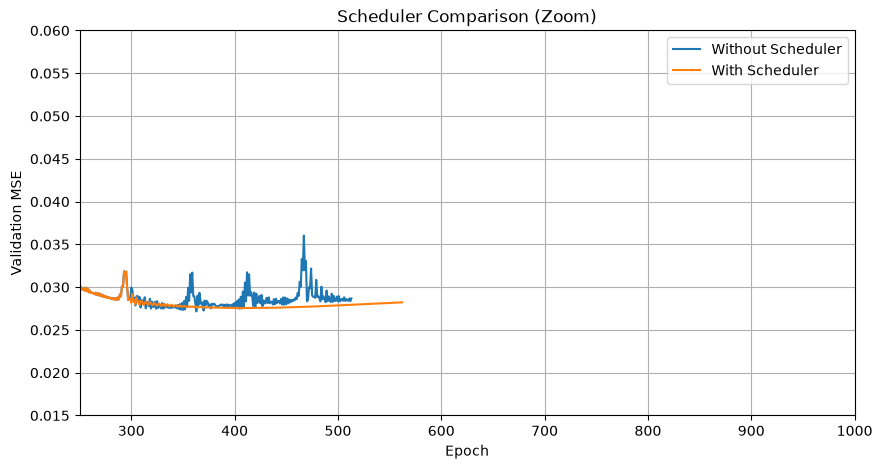

In [9]:


# 7. График Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(val1, label="Without Scheduler")
plt.plot(val2, label="With Scheduler")

plt.xlim(250, 1000)
plt.ylim(0.015, 0.06)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Scheduler Comparison (Zoom)")
plt.legend()
plt.grid()
plt.show()


### График изменения learning rate

У Scheduler должны появиться ступени уменьшения шага. Эта картинка показывает работу расписания, но сама по себе ничего не доказывает о качестве предсказаний.

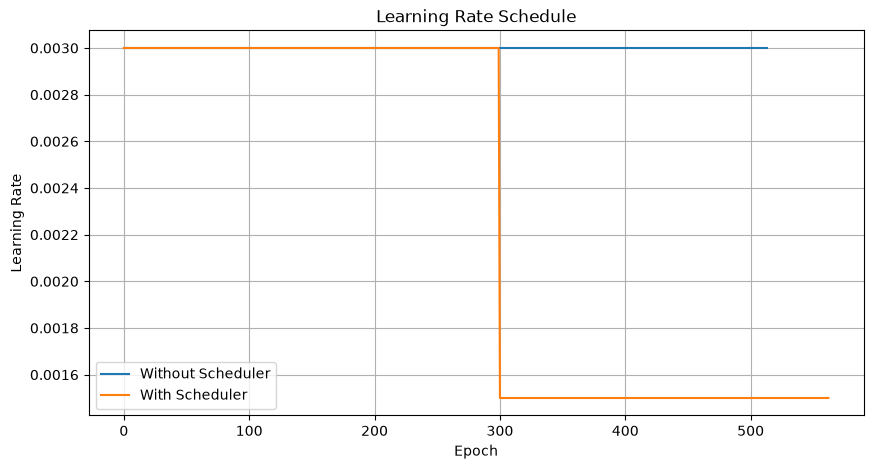


ЛУЧШИЕ РЕЗУЛЬТАТЫ:
Без Scheduler: Min Val = 0.02716 Epoch = 364


In [10]:


# 8. График Learning Rate
plt.figure(figsize=(10, 5))

plt.plot(lr1, label="Without Scheduler")
plt.plot(lr2, label="With Scheduler")

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.legend()
plt.grid()

plt.show()


print("\nЛУЧШИЕ РЕЗУЛЬТАТЫ:")

print(
    "Без Scheduler:",
    "Min Val =", round(min(val1), 5),
    "Epoch =", val1.index(min(val1)) + 1
)


### Выводим лучшие эпохи

Находим минимум каждой кривой validation и номер соответствующей эпохи.

In [11]:

print(
    "Со Scheduler:",
    "Min Val =", round(min(val2), 5),
    "Epoch =", val2.index(min(val2)) + 1
)

Со Scheduler: Min Val = 0.02756 Epoch = 413


## Выводы

StepLR уменьшает шаг обучения по расписанию, а ранняя остановка завершает обучение при отсутствии улучшения. Для сравнения вариантов смотрим минимальную validation MSE, лучшую эпоху и длительность обучения.


## Полный код


In [ ]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
import copy
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Создаём данные
x = torch.linspace(-3, 3, 200).reshape(-1, 1)
y = torch.sin(3 * x) + 0.3 * x

# Добавляем шум
y_noisy = y + 0.15 * torch.randn_like(y)

# Разделяем на Train и Validation
indices = torch.randperm(200)

train_idx = indices[:160]
val_idx = indices[160:]

x_train = x[train_idx]
y_train = y_noisy[train_idx]

x_val = x[val_idx]
y_val = y_noisy[val_idx]


# 2. Создаём нейросеть Very Deep
def create_model():
    return nn.Sequential(
        nn.Linear(1, 32),
        nn.Tanh(),
        nn.Linear(32, 32),
        nn.Tanh(),
        nn.Linear(32, 32),
        nn.Tanh(),
        nn.Linear(32, 1)
    )

best_val_loss = float("inf")
best_epoch = 0
best_weights = None

patience = 150
epochs_without_improvement = 0

# 3. Функция обучения

def train_model(use_scheduler):

    torch.manual_seed(42)
    model = create_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003
    )

    loss_fn = nn.MSELoss()

    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=300,
            gamma=0.5
        )

    train_history = []
    val_history = []
    lr_history = []

    # Настройки Early Stopping
    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    patience = 150
    epochs_without_improvement = 0

    for epoch in range(1000):

        # ОБУЧЕНИЕ
        model.train()
        optimizer.zero_grad()

        prediction = model(x_train)
        loss = loss_fn(prediction, y_train)

        loss.backward()

        current_lr = optimizer.param_groups[0]["lr"]
        lr_history.append(current_lr)

        optimizer.step()

        if use_scheduler:
            scheduler.step()

        # ПРОВЕРКА
        model.eval()

        with torch.no_grad():
            val_prediction = model(x_val)
            val_loss = loss_fn(val_prediction, y_val)

        train_history.append(loss.item())
        val_history.append(val_loss.item())

        # EARLY STOPPING
        if val_loss.item() < best_val_loss:

            best_val_loss = val_loss.item()
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1:4d} | "
                f"LR: {current_lr:.6f} | "
                f"Train: {loss.item():.5f} | "
                f"Val: {val_loss.item():.5f}"
            )

        # Остановка, если нет улучшений
        if epochs_without_improvement >= patience:
            print(f"Early Stopping на эпохе {epoch + 1}")
            break

    # Восстанавливаем лучшие веса
    model.load_state_dict(best_weights)

    print("Лучшая эпоха:", best_epoch)
    print("Лучший Validation MSE:", round(best_val_loss, 5))
    print()

    return train_history, val_history, lr_history

# 4. Обучаем без Scheduler
print("=== БЕЗ SCHEDULER ===")

train1, val1, lr1 = train_model(False)


# 5. Обучаем со Scheduler
print("\n=== СО SCHEDULER ===")

train2, val2, lr2 = train_model(True)


# 6. Сравниваем результаты
print("\nИТОГИ:")
print("Без Scheduler:", round(val1[-1], 5))
print("Со Scheduler:", round(val2[-1], 5))


# 7. График Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(val1, label="Without Scheduler")
plt.plot(val2, label="With Scheduler")

plt.xlim(250, 1000)
plt.ylim(0.015, 0.06)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Scheduler Comparison (Zoom)")
plt.legend()
plt.grid()
plt.show()


# 8. График Learning Rate
plt.figure(figsize=(10, 5))

plt.plot(lr1, label="Without Scheduler")
plt.plot(lr2, label="With Scheduler")

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.legend()
plt.grid()

plt.show()


print("\nЛУЧШИЕ РЕЗУЛЬТАТЫ:")

print(
    "Без Scheduler:",
    "Min Val =", round(min(val1), 5),
    "Epoch =", val1.index(min(val1)) + 1
)

print(
    "Со Scheduler:",
    "Min Val =", round(min(val2), 5),
    "Epoch =", val2.index(min(val2)) + 1
)